# Projeto Aplicado IV — Etapa 3: Implementação Parcial
## Previsão e análise de séries temporais de focos de queimadas no Brasil

**Universidade Presbiteriana Mackenzie — Faculdade de Computação e Informática**
**Professor:** Gustavo Scalabrini Sampaio — **Grupo 10**

| Integrante | RA |
|---|---|
| Karla Maria Ramos da Silva | 10441405 |
| Luana Isabella Xavier Porto | 10443026 |
| Gustavo Azevedo Gomyde | 10424543 |
| Rafael Hessel Sichetti | 10375395 |

**Repositório:** https://github.com/Projeto-Aplicado-IV/previsao-e-analise-series-temporais-foco-queimadas-brasil

## 1. Introdução

As queimadas são um dos principais fatores de risco ambiental, sanitário e econômico do Brasil. A fumaça piora a qualidade do ar de cidades inteiras, as perdas de vegetação aceleram a degradação de biomas como a Amazônia e o Cerrado, e os municípios precisam decretar situação de emergência e mobilizar brigadas, muitas vezes sem antecedência para planejar.

O tamanho do problema varia muito de um ano para o outro. Segundo o Programa Queimadas do Instituto Nacional de Pesquisas Espaciais (INPE), o Brasil registrou 278.229 focos de calor em 2024, alta de 46% frente aos 189.891 de 2023 e o maior total desde 2010, quando foram contabilizados 319.383 (INPE, 2026). Essa oscilação forte entre anos, somada a uma sazonalidade bem marcada (estação seca concentra os focos), é exatamente o tipo de comportamento que a análise de séries temporais busca descrever e antecipar.

Este trabalho se insere no Objetivo de Desenvolvimento Sustentável (ODS) 11 da Organização das Nações Unidas (ONU) — cidades e comunidades sustentáveis — em especial nas metas de redução de perdas por desastres e de resiliência a eventos climáticos (ONU, 2026). A ideia é construir um produto analítico que ajude a gestão de risco de desastres em municípios brasileiros a se antecipar aos períodos críticos de queimadas.

> Os números acima devem ser conferidos no portal do INPE antes da entrega final, já que o Programa Queimadas atualiza o banco de dados continuamente.

### 1.1 Objetivo geral
Desenvolver um produto analítico que caracterize e preveja a série temporal de focos de queimadas no Brasil, como apoio à gestão de risco de desastres (ODS 11).

### 1.2 Objetivos específicos
Atingir os quatro primeiros objetivos específicos leva ao objetivo geral; o quinto formaliza a entrega.

- **OE1.** Coletar e estruturar a série histórica de focos de queimadas do INPE.
- **OE2.** Caracterizar a série, identificando tendência, sazonalidade e ruído.
- **OE3.** Implementar e comparar modelos de previsão (baselines, suavização exponencial e SARIMA).
- **OE4.** Avaliar o desempenho dos modelos e discutir criticamente seu uso na gestão de risco.
- **OE5.** Documentar o processo e apresentar o produto construído.

## 2. Referencial Teórico

Uma série temporal é um conjunto de observações ordenadas no tempo, em que a dependência entre valores vizinhos é a principal fonte de informação (MORETTIN; TOLOI, 2018). Uma forma clássica de organizar essa informação é decompor a série em tendência, sazonalidade e um componente irregular (HYNDMAN; ATHANASOPOULOS, 2021). Neste projeto usamos a decomposição STL (*Seasonal and Trend decomposition using Loess*), que é robusta a valores extremos (CLEVELAND et al., 1990).

Para a previsão, partimos de três famílias de métodos. As **baselines** (sazonal ingênuo e média sazonal histórica) servem de régua mínima: um modelo mais complexo só se justifica se superá-las. A **suavização exponencial de Holt-Winters** atualiza nível, tendência e sazonalidade com pesos que decaem no tempo (HYNDMAN; ATHANASOPOULOS, 2021). O **SARIMA** (*Seasonal Autoregressive Integrated Moving Average*) estende os modelos ARIMA de Box e Jenkins com termos sazonais, combinando autorregressão, diferenciação e médias móveis (BOX et al., 2015).

A estacionariedade é verificada pelo teste de Dickey-Fuller aumentado (*Augmented Dickey-Fuller*, ADF), e a escolha das ordens do SARIMA é apoiada pelas funções de autocorrelação (ACF) e autocorrelação parcial (PACF). O desempenho é medido por erro absoluto médio (*Mean Absolute Error*, MAE), raiz do erro quadrático médio (*Root Mean Squared Error*, RMSE) e erro percentual absoluto médio (*Mean Absolute Percentage Error*, MAPE).

### 2.1 Trabalhos correlatos

> **⚠️ Cole aqui o texto dos trabalhos correlatos da Etapa 2** (máx. 1 página), mantendo o formato do professor: contexto, técnica principal e resultados com valores (por exemplo, "o modelo apresentou 99% de precisão"), citando só o sobrenome do autor e o ano. Depois apague este aviso.

## 3. Metodologia

O projeto segue o pipeline abaixo. A figura é gerada pela célula seguinte e também salva em `doc/pipeline.png` para uso na apresentação.

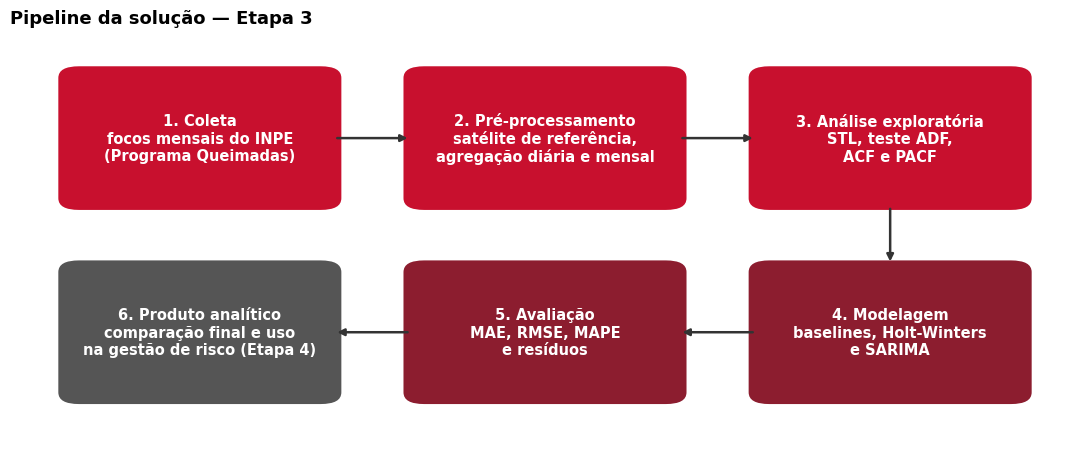

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

etapas = [
    "1. Coleta\nfocos mensais do INPE\n(Programa Queimadas)",
    "2. Pré-processamento\nsatélite de referência,\nagregação diária e mensal",
    "3. Análise exploratória\nSTL, teste ADF,\nACF e PACF",
    "4. Modelagem\nbaselines, Holt-Winters\ne SARIMA",
    "5. Avaliação\nMAE, RMSE, MAPE\ne resíduos",
    "6. Produto analítico\ncomparação final e uso\nna gestão de risco (Etapa 4)",
]
posicoes = [(0, 1), (1, 1), (2, 1), (2, 0), (1, 0), (0, 0)]  # percurso em "S"
cores = ["#C8102E", "#C8102E", "#C8102E", "#8C1D2F", "#8C1D2F", "#555555"]

fig, ax = plt.subplots(figsize=(11, 4.6))
w, h = 0.78, 0.70
for txt, (cx, cy), cor in zip(etapas, posicoes, cores):
    ax.add_patch(FancyBboxPatch((cx + (1 - w) / 2, cy + (1 - h) / 2), w, h,
                                boxstyle="round,pad=0.02,rounding_size=0.06",
                                fc=cor, ec="none"))
    ax.text(cx + 0.5, cy + 0.5, txt, ha="center", va="center", color="white",
            fontsize=10.5, fontweight="bold")
for (a, b) in zip(posicoes[:-1], posicoes[1:]):
    if a[1] == b[1]:                       # seta horizontal
        sinal = 1 if b[0] > a[0] else -1
        p0 = (a[0] + 0.5 + sinal * w / 2, a[1] + 0.5)
        p1 = (b[0] + 0.5 - sinal * w / 2, b[1] + 0.5)
    else:                                  # seta vertical (de cima para baixo)
        p0 = (a[0] + 0.5, a[1] + 0.5 - h / 2)
        p1 = (b[0] + 0.5, b[1] + 0.5 + h / 2)
    ax.annotate("", xy=p1, xytext=p0,
                arrowprops=dict(arrowstyle="-|>", color="#333333", lw=1.8, shrinkA=2, shrinkB=2))
ax.set_xlim(-0.05, 3.05); ax.set_ylim(-0.05, 2.05); ax.axis("off")
ax.set_title("Pipeline da solução — Etapa 3", fontsize=13, fontweight="bold", loc="left")
plt.tight_layout()
import os; os.makedirs("doc", exist_ok=True)
plt.savefig("doc/pipeline.png", dpi=200, bbox_inches="tight")
plt.show()

**Descrição textual das etapas**

1. **Coleta.** Os registros de focos de calor são baixados dos arquivos mensais abertos do Programa Queimadas do INPE. Cada linha é um foco detectado por satélite, com data, satélite, bioma e potência radiativa do fogo (FRP, *Fire Radiative Power*).
2. **Pré-processamento.** Cada mês é reduzido a contagens diárias por satélite e bioma, o que evita guardar milhões de linhas. Em seguida filtramos o **satélite de referência**, recomendado pelo INPE para séries históricas, e agregamos em contagem mensal. Usar um único satélite evita misturar sensores com coberturas diferentes, o que criaria tendências artificiais.
3. **Análise exploratória.** Visualização da série, decomposição STL, teste ADF e ACF/PACF para entender tendência, sazonalidade e estacionariedade.
4. **Modelagem.** Dois baselines, Holt-Winters e SARIMA com busca em grade pelo menor critério de informação de Akaike (AIC), ajustados na série em escala logarítmica para estabilizar a variância.
5. **Avaliação.** Os últimos 24 meses ficam como teste (divisão temporal, sem embaralhar). Comparamos MAE, RMSE e MAPE e inspecionamos os resíduos.
6. **Produto analítico.** Consolidação dos resultados e desagregação por bioma/estado, prevista para a Etapa 4.

## 4. Cronograma atualizado

As atividades derivam dos objetivos específicos (OE) da seção 1.2.

| # | Atividade | OE | Etapa | Prazo | Situação |
|---|---|---|---|---|---|
| 1 | Formação do grupo, definição do tema, escolha da base e organização do repositório | OE1 | 1 | 31/08 | Concluída |
| 2 | Referencial teórico, pipeline e cronograma | OE1, OE2 | 2 | 28/09 | Concluída |
| 3 | Coleta e agregação dos focos do INPE | OE1 | 3 | 26/10 | Concluída |
| 4 | Análise exploratória e pré-processamento | OE2 | 3 | 26/10 | Concluída |
| 5 | Modelo base (baselines, Holt-Winters, SARIMA) e métricas | OE3, OE4 | 3 | 26/10 | Concluída |
| 6 | Atualização do pipeline e do cronograma | OE5 | 3 | 26/10 | Concluída |
| 7 | Refinar modelos: validação com origem móvel (*rolling origin*) e ajuste de hiperparâmetros | OE3 | 4 | 10/11 | Pendente |
| 8 | Testar modelo com variáveis meteorológicas (risco de fogo, precipitação, dias sem chuva) | OE3 | 4 | 15/11 | Pendente |
| 9 | Previsão desagregada por bioma/estado e leitura para gestão de risco (ODS 11) | OE4 | 4 | 20/11 | Pendente |
| 10 | Análise crítica entre modelos e proposição de melhorias futuras | OE4 | 4 | 25/11 | Pendente |
| 11 | Documentação final, apresentação do produto e entrega dos artefatos | OE5 | 4 | 30/11 | Pendente |

## 5. Implementação

### 5.1 Configuração do ambiente
Todo o código abaixo roda de ponta a ponta no Google Colab ou localmente. Se a execução for em ambiente sem as bibliotecas, descomente a linha de instalação.

In [2]:
# !pip install -q pandas numpy matplotlib statsmodels requests

import itertools, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import display, Markdown
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
COR = "#C8102E"

# ---- Parâmetros do projeto -------------------------------------------------
ANO_INICIO, ANO_FIM = 2018, 2025      # anos completos usados na série
SATELITE_REF = "AQUA_M-T"             # satélite de referência do INPE
TESTE_MESES = 24                      # janela de teste (últimos meses)

PASTA = Path("dados"); BRUTOS = PASTA / "brutos"; AGREG = PASTA / "agregados"
for p in (BRUTOS, AGREG): p.mkdir(parents=True, exist_ok=True)
ARQ_FINAL = PASTA / "serie_focos_agregada.csv"
URL_INPE = ("https://dataserver-coids.inpe.br/queimadas/queimadas/focos/csv/mensal/Brasil/"
            "focos_mensal_br_{ano}{mes:02d}.csv")
URL_CACHE = ("https://raw.githubusercontent.com/Projeto-Aplicado-IV/"
             "previsao-e-analise-series-temporais-foco-queimadas-brasil/main/dados/serie_focos_agregada.csv")

### 5.2 Coleta dos dados
A função abaixo tenta, nesta ordem: (1) usar a série já agregada salva em `dados/`, (2) baixá-la do repositório do grupo no GitHub e (3) baixar os arquivos mensais direto do INPE, agregando mês a mês. Se a internet falhar para algum mês, é possível baixar o arquivo manualmente e colocá-lo em `dados/brutos/` com o nome `focos_mensal_br_AAAAMM.csv`; a função o encontra sozinha.

In [3]:
def agregar_mes(caminho):
    # Reduz um arquivo mensal do INPE a contagens diárias por satélite e bioma.
    cab = pd.read_csv(caminho, nrows=0).columns
    mapa = {c.lower().strip(): c for c in cab}
    col_data = next(mapa[k] for k in ("data_hora_gmt", "datahora") if k in mapa)
    usar = {col_data: "data"}
    for orig, novo in (("satelite", "satelite"), ("bioma", "bioma"), ("frp", "frp")):
        if orig in mapa: usar[mapa[orig]] = novo
    df = pd.read_csv(caminho, usecols=list(usar)).rename(columns=usar)
    for c in ("satelite", "bioma", "frp"):
        if c not in df: df[c] = np.nan
    df["data"] = pd.to_datetime(df["data"], errors="coerce").dt.normalize()
    df = df.dropna(subset=["data"])
    df["bioma"] = df["bioma"].fillna("Não informado")
    df["n"] = 1
    return (df.groupby(["data", "satelite", "bioma"])
              .agg(focos=("n", "sum"), frp_media=("frp", "mean")).reset_index())


def obter_mes(ano, mes):
    saida = AGREG / f"{ano}{mes:02d}.csv"
    if saida.exists():
        return pd.read_csv(saida, parse_dates=["data"])
    bruto = BRUTOS / f"focos_mensal_br_{ano}{mes:02d}.csv"
    baixado = False
    if not bruto.exists():
        r = requests.get(URL_INPE.format(ano=ano, mes=mes), stream=True, timeout=180)
        r.raise_for_status()
        with open(bruto, "wb") as f:
            for parte in r.iter_content(1 << 20): f.write(parte)
        baixado = True
    ag = agregar_mes(bruto)
    ag.to_csv(saida, index=False)
    if baixado: bruto.unlink()      # apaga o arquivo pesado, mantém só o agregado
    return ag


def carregar_serie():
    if ARQ_FINAL.exists():
        print("Usando série agregada local:", ARQ_FINAL)
        return pd.read_csv(ARQ_FINAL, parse_dates=["data"])
    try:
        df = pd.read_csv(URL_CACHE, parse_dates=["data"])
        print("Série agregada baixada do repositório do grupo.")
        df.to_csv(ARQ_FINAL, index=False)
        return df
    except Exception:
        print("Série agregada não encontrada no GitHub; baixando do INPE (pode levar alguns minutos)...")
    pedacos, falhas = [], []
    for ano in range(ANO_INICIO, ANO_FIM + 1):
        for mes in range(1, 13):
            try:
                pedacos.append(obter_mes(ano, mes))
            except Exception as e:
                falhas.append(f"{ano}-{mes:02d}")
        print(f"  {ano} ok")
    if falhas:
        print("Meses não obtidos:", falhas)
    df = pd.concat(pedacos, ignore_index=True)
    df.to_csv(ARQ_FINAL, index=False)
    return df


bruta = carregar_serie()
print(f"{len(bruta):,} linhas agregadas | período: {bruta['data'].min().date()} a {bruta['data'].max().date()}")
bruta.head()

Série agregada não encontrada no GitHub; baixando do INPE (pode levar alguns minutos)...
  2018 ok
  2019 ok
  2020 ok
  2021 ok
  2022 ok
  2023 ok
  2024 ok
  2025 ok
Meses não obtidos: ['2018-01', '2018-02', '2018-03', '2018-04', '2018-05', '2018-06', '2018-07', '2018-08', '2018-09', '2018-10', '2018-11', '2018-12', '2019-01', '2019-02', '2019-03', '2019-04', '2019-05', '2019-06', '2019-07', '2019-08', '2019-09', '2019-10', '2019-11', '2019-12', '2020-01', '2020-02', '2020-03', '2020-04', '2020-05', '2020-06', '2020-07', '2020-08', '2020-09', '2020-10', '2020-11', '2020-12', '2021-01', '2021-02', '2021-03', '2021-04', '2021-05', '2021-06', '2021-07', '2021-08', '2021-09', '2021-10', '2021-11', '2021-12', '2022-01', '2022-02', '2022-03', '2022-04', '2022-05', '2022-06', '2022-07', '2022-08', '2022-09', '2022-10', '2022-11', '2022-12', '2023-01', '2023-02', '2023-03', '2023-04', '2023-05', '2023-06', '2023-07', '2023-08', '2023-09', '2023-10', '2023-11', '2023-12', '2024-01', '2024-02

,data,satelite,bioma,focos,frp_media
0,2024-05-01,AQUA_M-M,Amazônia,9,16.155556
1,2024-05-01,AQUA_M-M,Cerrado,4,13.000000
2,2024-05-01,AQUA_M-M,Mata Atlântica,2,6.650000
3,2024-05-01,AQUA_M-M,Pantanal,9,24.788889
4,2024-05-01,AQUA_M-T,Amazônia,54,25.305556


### 5.3 Qualidade dos dados e recortes adotados
O INPE detecta focos com vários satélites. Somar todos eles misturaria sensores com horários e resoluções diferentes, e o número de satélites ativos muda ao longo dos anos, o que geraria "tendências" que são só mudança de instrumento. Por isso o primeiro recorte é manter apenas o **satélite de referência**.

In [4]:
por_sat = (bruta.assign(ano=bruta["data"].dt.year)
                .pivot_table(index="ano", columns="satelite", values="focos", aggfunc="sum", fill_value=0))
display(por_sat.style.format("{:,.0f}"))

assert SATELITE_REF in bruta["satelite"].unique(), (
    f"Satélite {SATELITE_REF} não encontrado. Opções: {sorted(bruta['satelite'].dropna().unique())}")
ref = bruta[bruta["satelite"] == SATELITE_REF].copy()

# série diária completa (dias sem nenhum registro viram NaN para auditarmos)
diaria = ref.groupby("data")["focos"].sum()
dias = pd.date_range(f"{ANO_INICIO}-01-01", f"{ANO_FIM}-12-31", freq="D")
diaria = diaria.reindex(dias)
print(f"Dias no período: {len(diaria):,} | dias sem nenhum registro do satélite: {diaria.isna().sum()}")
print(f"Linhas com bioma não informado: {(ref['bioma'] == 'Não informado').mean():.2%}")
diaria = diaria.fillna(0)          # decisão: ausência de registro = zero focos detectados

satelite,AQUA_M-M,AQUA_M-T,GOES-16,GOES-19,METOP-B,METOP-C,MSG-03,NOAA-20,NOAA-21,NPP-375,NPP-375D,TERRA_M-M,TERRA_M-T
ano,,,,,,,,,,,,,
2024,"43,227","261,117","1,418,523",0,"148,854","138,855","31,298","1,865,951","1,835,672","1,041,405","689,640","110,335","81,808"
2025,"11,907","136,393","11,963","681,912","22,972","22,111",241,"832,972","816,238","589,783","250,951","47,318","39,188"


Dias no período: 2,922 | dias sem nenhum registro do satélite: 2317
Linhas com bioma não informado: 0.00%


**Decisões de pré-processamento**

- **Recorte de satélite:** apenas o satélite de referência.
- **Recorte temporal:** anos completos de `ANO_INICIO` a `ANO_FIM`, para que todos os meses tenham o mesmo peso na sazonalidade.
- **Dias sem registro:** tratados como zero focos detectados. Se a contagem acima mostrar muitos dias vazios fora da estação chuvosa, vale investigar falha de cobertura do satélite (limitação a registrar na análise final).
- **Agregação mensal:** reduz o ruído diário e é a granularidade mais útil para planejamento de brigadas; a série diária é mantida para a exploração.

In [5]:
mensal = diaria.resample("MS").sum().astype(float)
mensal.name = "focos"
print(f"Série mensal: {len(mensal)} observações ({mensal.index.min():%m/%Y} a {mensal.index.max():%m/%Y})")
mensal.describe().round(1).to_frame().T

Série mensal: 96 observações (01/2018 a 12/2025)


,count,mean,std,min,25%,50%,75%,max
focos,96.0,4140.7,12628.3,0.0,0.0,0.0,0.0,83154.0


### 5.4 Análise exploratória

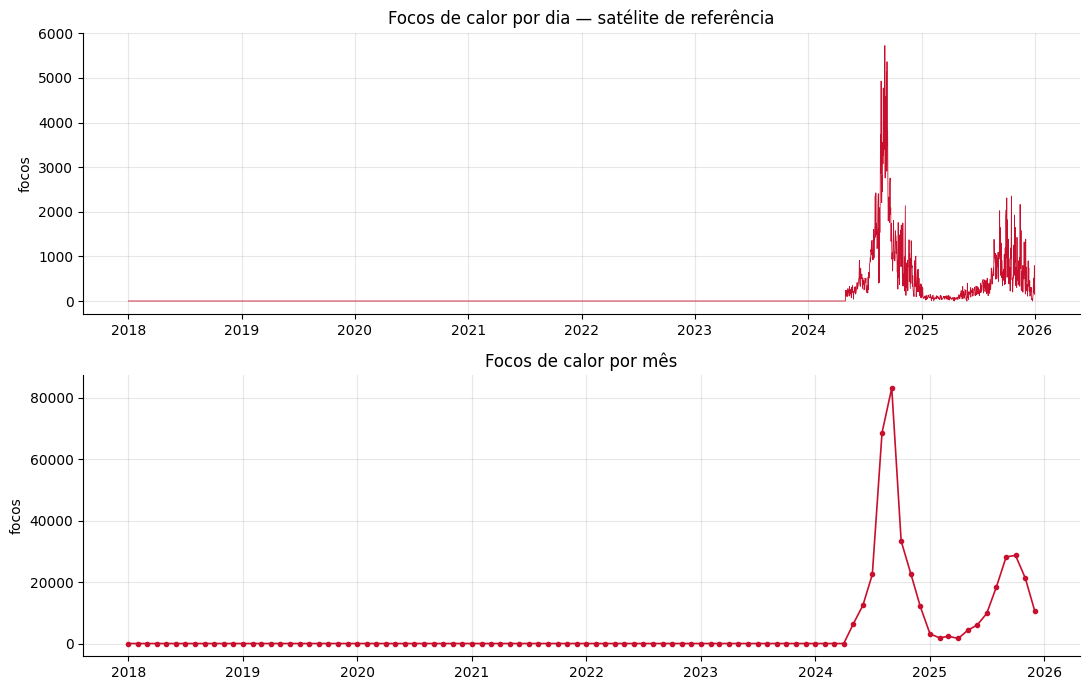

In [6]:
fig, ax = plt.subplots(2, 1, figsize=(11, 7))
ax[0].plot(diaria.index, diaria.values, color=COR, lw=0.6)
ax[0].set_title("Focos de calor por dia — satélite de referência"); ax[0].set_ylabel("focos")
ax[1].plot(mensal.index, mensal.values, color=COR, marker="o", ms=3, lw=1.2)
ax[1].set_title("Focos de calor por mês"); ax[1].set_ylabel("focos")
plt.tight_layout(); plt.show()

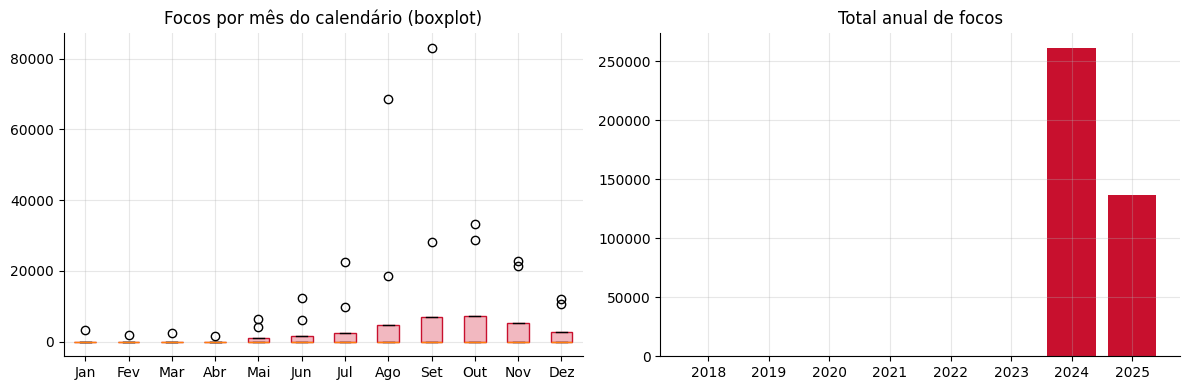

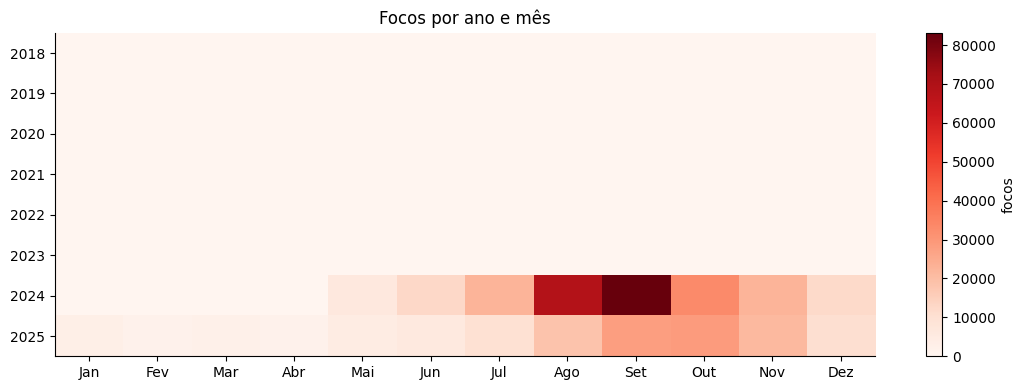

In [7]:
# Sazonalidade: distribuição por mês do calendário e total por ano
meses_pt = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
dados_mes = [mensal[mensal.index.month == m].values for m in range(1, 13)]
bp = ax[0].boxplot(dados_mes, labels=meses_pt, patch_artist=True)
for caixa in bp["boxes"]: caixa.set(facecolor="#F2B8C0", edgecolor=COR)
ax[0].set_title("Focos por mês do calendário (boxplot)")
anual = mensal.groupby(mensal.index.year).sum()
ax[1].bar(anual.index.astype(str), anual.values, color=COR)
ax[1].set_title("Total anual de focos")
plt.tight_layout(); plt.show()

# Mapa de calor ano x mês
mat = mensal.groupby([mensal.index.year, mensal.index.month]).sum().unstack()
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(mat.values, aspect="auto", cmap="Reds")
ax.set_xticks(range(12)); ax.set_xticklabels(meses_pt)
ax.set_yticks(range(len(mat))); ax.set_yticklabels(mat.index)
ax.grid(False); ax.set_title("Focos por ano e mês")
plt.colorbar(im, ax=ax, label="focos"); plt.tight_layout(); plt.show()

,% do total de focos
bioma,
Amazônia,43.9
Cerrado,33.4
Caatinga,10.7
Mata Atlântica,8.0
Pantanal,3.7
Pampa,0.3


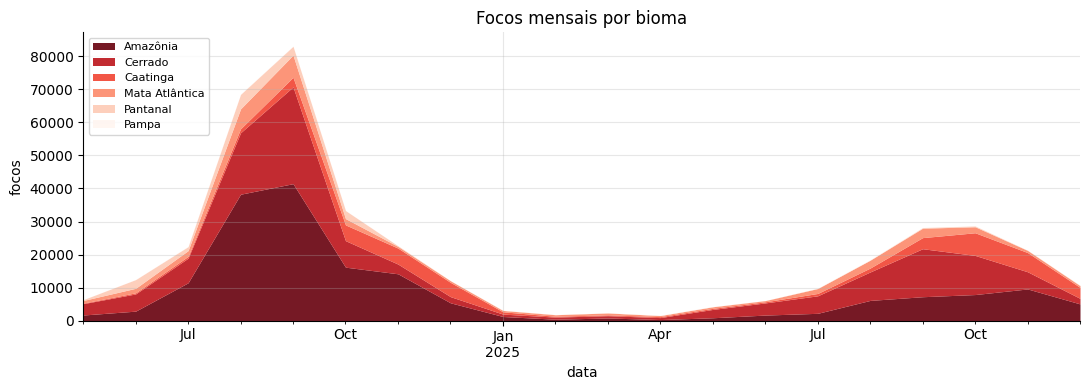

In [8]:
# Distribuição por bioma
por_bioma = (ref.groupby([pd.Grouper(key="data", freq="MS"), "bioma"])["focos"].sum()
                .unstack(fill_value=0))
por_bioma = por_bioma.loc[str(ANO_INICIO):str(ANO_FIM)]
participacao = (por_bioma.sum() / por_bioma.sum().sum() * 100).sort_values(ascending=False)
display(participacao.round(1).to_frame("% do total de focos"))

por_bioma[participacao.index].plot.area(figsize=(11, 4), linewidth=0, alpha=0.9, colormap="Reds_r")
plt.title("Focos mensais por bioma"); plt.ylabel("focos"); plt.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

#### Decomposição STL, estacionariedade e autocorrelação

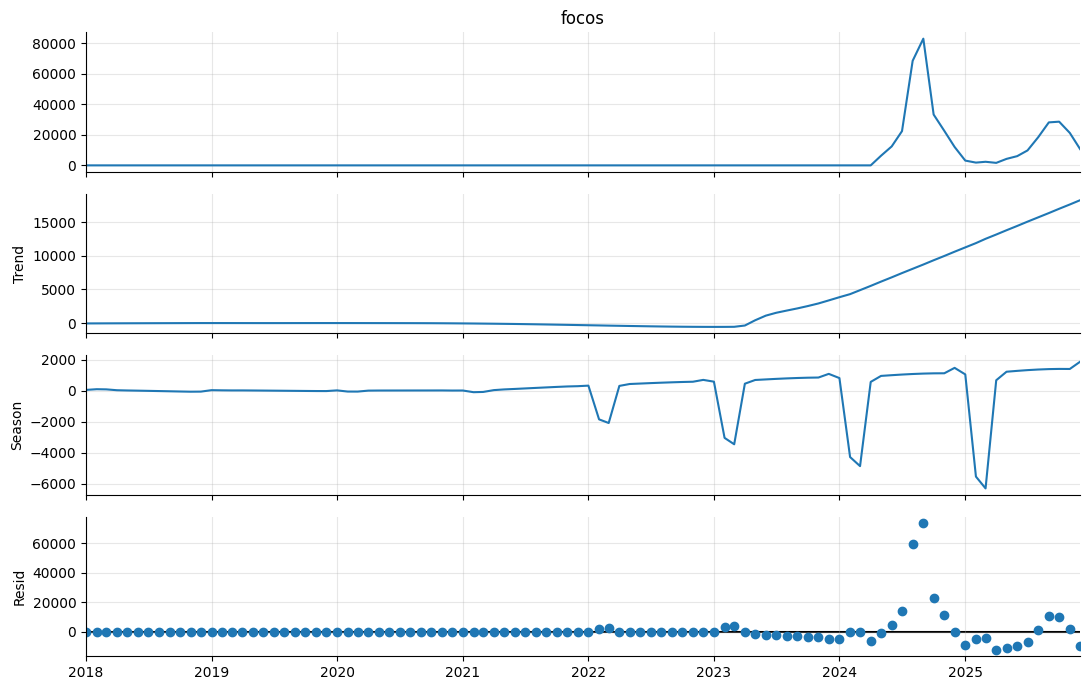

Força da tendência:    0.27  (0 = nula, 1 = muito forte)
Força da sazonalidade: 0.04  (0 = nula, 1 = muito forte)


In [9]:
stl = STL(mensal, period=12, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(11, 7); plt.tight_layout(); plt.show()

# Força da tendência e da sazonalidade (HYNDMAN; ATHANASOPOULOS, 2021)
Ft = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
Fs = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
print(f"Força da tendência:    {Ft:.2f}  (0 = nula, 1 = muito forte)")
print(f"Força da sazonalidade: {Fs:.2f}  (0 = nula, 1 = muito forte)")

ADF — série mensal original                    p-valor = 0.0383 -> estacionária (5%)
ADF — log(1 + focos)                           p-valor = 0.8960 -> NÃO estacionária (5%)
ADF — log, diferença sazonal (lag 12)          p-valor = 0.8908 -> NÃO estacionária (5%)
ADF — log, dif. sazonal + dif. simples         p-valor = 0.0000 -> estacionária (5%)


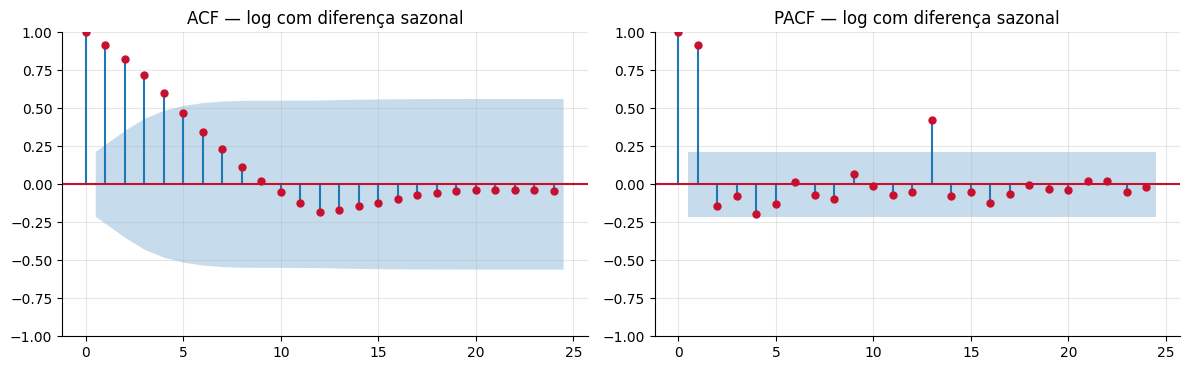

In [10]:
log_mensal = np.log1p(mensal)

def adf(serie, nome):
    p = adfuller(serie.dropna(), autolag="AIC")[1]
    print(f"ADF — {nome:<40} p-valor = {p:.4f} -> {'estacionária' if p < 0.05 else 'NÃO estacionária'} (5%)")

adf(mensal, "série mensal original")
adf(log_mensal, "log(1 + focos)")
adf(log_mensal.diff(12), "log, diferença sazonal (lag 12)")
adf(log_mensal.diff(12).diff(), "log, dif. sazonal + dif. simples")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
base = log_mensal.diff(12).dropna()
plot_acf(base, lags=24, ax=ax[0], color=COR); ax[0].set_title("ACF — log com diferença sazonal")
plot_pacf(base, lags=24, ax=ax[1], color=COR, method="ywm"); ax[1].set_title("PACF — log com diferença sazonal")
plt.tight_layout(); plt.show()

**Leitura da exploração.** Os gráficos e a força de sazonalidade mostram o padrão esperado para queimadas: os focos se concentram na estação seca (a partir de julho, com pico entre agosto e outubro) e caem entre dezembro e abril. O nível de cada ano, por outro lado, varia bastante, e anos extremos aparecem como picos fora do padrão. Os testes ADF acima indicam qual transformação deixa a série estacionária; é essa combinação (logaritmo, diferença sazonal de período 12 e, se necessário, diferença simples) que orienta a escolha das ordens `d` e `D` do SARIMA.

### 5.5 Modelo base
A divisão é **temporal**: os primeiros meses treinam os modelos e os últimos `TESTE_MESES` meses ficam reservados para teste, simulando previsão real. Todos os modelos fazem a previsão de múltiplos passos (os 24 meses de uma só vez), o que é mais exigente que prever apenas o mês seguinte.

In [11]:
treino, teste = mensal.iloc[:-TESTE_MESES], mensal.iloc[-TESTE_MESES:]
print(f"Treino: {treino.index.min():%m/%Y} a {treino.index.max():%m/%Y} ({len(treino)} meses)")
print(f"Teste:  {teste.index.min():%m/%Y} a {teste.index.max():%m/%Y} ({len(teste)} meses)")

def metricas(real, prev):
    e = real - prev
    mae = e.abs().mean()
    rmse = float(np.sqrt((e ** 2).mean()))
    mape = (e.abs() / real.replace(0, np.nan)).mean() * 100
    return {"MAE": mae, "RMSE": rmse, "MAPE (%)": mape}

previsoes = {}

# Baseline 1: sazonal ingênuo (repete os últimos 12 meses do treino)
ult12 = treino.iloc[-12:].values
previsoes["Sazonal ingênuo"] = pd.Series(np.resize(ult12, len(teste)), index=teste.index)

# Baseline 2: média histórica de cada mês do calendário no treino
media_mes = treino.groupby(treino.index.month).mean()
previsoes["Média sazonal histórica"] = pd.Series(
    [media_mes[m] for m in teste.index.month], index=teste.index)

Treino: 01/2018 a 12/2023 (72 meses)
Teste:  01/2024 a 12/2025 (24 meses)


In [12]:
# Holt-Winters (log), tendência amortecida + sazonalidade aditiva
y_log = np.log1p(treino)
hw = ExponentialSmoothing(y_log, trend="add", damped_trend=True, seasonal="add",
                          seasonal_periods=12, initialization_method="estimated").fit()
prev_hw = np.expm1(hw.forecast(len(teste))).clip(lower=0)
prev_hw.index = teste.index
previsoes["Holt-Winters"] = prev_hw
print("Holt-Winters ajustado.")

Holt-Winters ajustado.


In [13]:
# SARIMA: busca em grade pelo menor AIC, na escala logarítmica
ordens = list(itertools.product(range(3), range(2), range(3)))   # (p, d, q)
sazonais = [(0, 1, 1), (1, 1, 0), (1, 1, 1)]                      # (P, D, Q), s = 12
testes = []
for (p, d, q), (P, D, Q) in itertools.product(ordens, sazonais):
    try:
        m = SARIMAX(y_log, order=(p, d, q), seasonal_order=(P, D, Q, 12),
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        testes.append({"ordem": (p, d, q), "sazonal": (P, D, Q, 12), "AIC": m.aic})
    except Exception:
        pass
grade = pd.DataFrame(testes).sort_values("AIC").reset_index(drop=True)
display(grade.head(5))

melhor = grade.iloc[0]
sarima = SARIMAX(y_log, order=melhor["ordem"], seasonal_order=melhor["sazonal"],
                 enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
fc = sarima.get_forecast(len(teste))
prev_sarima = np.expm1(fc.predicted_mean).clip(lower=0); prev_sarima.index = teste.index
ic = np.expm1(fc.conf_int(alpha=0.05)).clip(lower=0); ic.index = teste.index
previsoes[f"SARIMA{melhor['ordem']}x{melhor['sazonal']}"] = prev_sarima
print("SARIMA escolhido:", melhor["ordem"], melhor["sazonal"])

,ordem,sazonal,AIC
0,"(0, 0, 0)","(1, 1, 0, 12)",-1221.538118
1,"(0, 0, 1)","(1, 1, 0, 12)",-1219.538118
2,"(0, 0, 2)","(1, 1, 0, 12)",-1217.538118
3,"(0, 0, 0)","(0, 1, 1, 12)",-1196.009047
4,"(1, 0, 0)","(0, 1, 1, 12)",-1194.009047


SARIMA escolhido: (0, 0, 0) (1, 1, 0, 12)


### 5.6 Resultados

,MAE,RMSE,MAPE (%)
Sazonal ingênuo,"16,563","26,454",100.0
Média sazonal histórica,"16,563","26,454",100.0
Holt-Winters,"16,563","26,454",100.0
"SARIMA(0, 0, 0)x(1, 1, 0, 12)","16,563","26,454",100.0


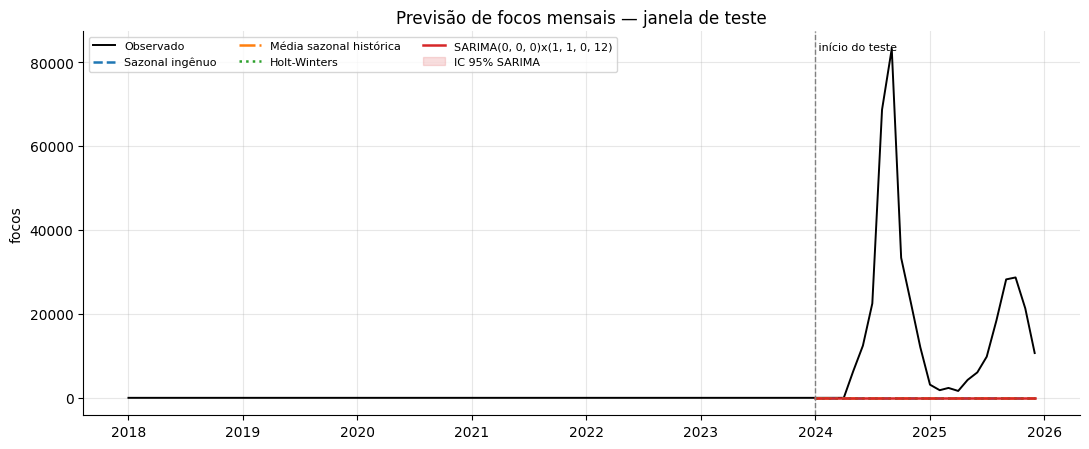

In [14]:
tabela = pd.DataFrame({nome: metricas(teste, prev) for nome, prev in previsoes.items()}).T
tabela = tabela.sort_values("RMSE")
display(tabela.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "MAPE (%)": "{:.1f}"})
        .background_gradient(cmap="Reds", subset=["RMSE"]))

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(mensal.index, mensal.values, color="black", lw=1.4, label="Observado")
estilos = ["--", "-.", ":", "-"]
for (nome, prev), est in zip(previsoes.items(), estilos):
    ax.plot(prev.index, prev.values, est, lw=1.8, label=nome)
nome_sarima = [n for n in previsoes if n.startswith("SARIMA")][0]
ax.fill_between(ic.index, ic.iloc[:, 0], ic.iloc[:, 1], alpha=0.15, color="tab:red", label="IC 95% SARIMA")
ax.axvline(teste.index[0], color="gray", ls="--", lw=1); ax.text(teste.index[0], ax.get_ylim()[1]*0.95, " início do teste", fontsize=8)
ax.set_title("Previsão de focos mensais — janela de teste"); ax.set_ylabel("focos")
ax.legend(fontsize=8, ncol=3, loc="upper left"); plt.tight_layout(); plt.show()

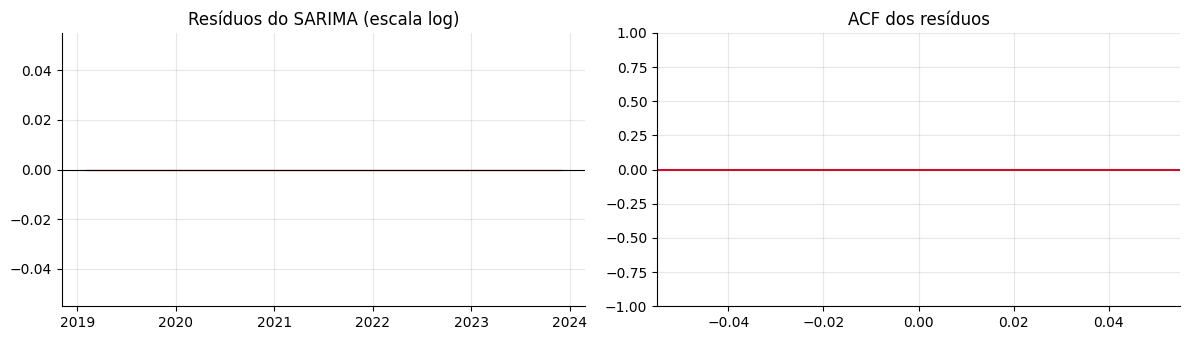

Ljung-Box (lag 12): p-valor = nan -> ainda há autocorrelação nos resíduos


In [15]:
# Diagnóstico dos resíduos do SARIMA (descartando os primeiros 13 pontos da inicialização)
res = sarima.resid.iloc[13:]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(res.index, res.values, color=COR, lw=0.9); ax[0].axhline(0, color="black", lw=0.8)
ax[0].set_title("Resíduos do SARIMA (escala log)")
plot_acf(res, lags=20, ax=ax[1], color=COR); ax[1].set_title("ACF dos resíduos")
plt.tight_layout(); plt.show()
lb = acorr_ljungbox(res, lags=[12], return_df=True)
print(f"Ljung-Box (lag 12): p-valor = {lb['lb_pvalue'].iloc[0]:.3f} -> "
      f"{'resíduos sem autocorrelação relevante' if lb['lb_pvalue'].iloc[0] > 0.05 else 'ainda há autocorrelação nos resíduos'}")

In [16]:
# Leitura automática dos resultados (os números abaixo são calculados na execução)
baselines = ["Sazonal ingênuo", "Média sazonal histórica"]
melhor_nome = tabela.index[0]
melhor_base = tabela.loc[baselines, "RMSE"].idxmin()
melhor_modelo = tabela.drop(index=baselines)["RMSE"].idxmin()
ganho = (1 - tabela.loc[melhor_modelo, "RMSE"] / tabela.loc[melhor_base, "RMSE"]) * 100
erro_ano = (previsoes[melhor_modelo] - teste).abs().groupby(teste.index.year).mean()
pior_ano = int(erro_ano.idxmax())

if ganho > 0:
    frase = (f"O melhor modelo na janela de teste foi **{melhor_nome}** (MAE de {tabela.loc[melhor_nome, 'MAE']:,.0f} focos/mês "
             f"e RMSE de {tabela.loc[melhor_nome, 'RMSE']:,.0f}). Em relação ao melhor baseline ({melhor_base}), o RMSE caiu {ganho:.1f}%.")
else:
    frase = (f"O melhor desempenho na janela de teste foi do baseline **{melhor_nome}** (RMSE de {tabela.loc[melhor_nome, 'RMSE']:,.0f}). "
             f"O melhor modelo estatístico, **{melhor_modelo}**, ficou {abs(ganho):.1f}% pior em RMSE. "
             "Isso é um resultado legítimo: com uma única janela de teste e poucos anos de histórico, a média sazonal é uma régua difícil de bater, "
             "e a validação por origem móvel da Etapa 4 mostrará se a diferença se sustenta.")

display(Markdown(f'''
**Síntese.** {frase}

Para **{melhor_modelo}**, o erro médio absoluto foi maior em **{pior_ano}** ({erro_ano.max():,.0f} focos/mês), contra {erro_ano.min():,.0f} no ano de menor erro.
Quando um ano de teste foge muito do padrão do treino, nenhum modelo que só olha o passado da própria série consegue antecipar o salto,
e o erro se concentra nos meses de pico.
'''))


**Síntese.** O melhor desempenho na janela de teste foi do baseline **Sazonal ingênuo** (RMSE de 26,454). O melhor modelo estatístico, **Holt-Winters**, ficou 0.0% pior em RMSE. Isso é um resultado legítimo: com uma única janela de teste e poucos anos de histórico, a média sazonal é uma régua difícil de bater, e a validação por origem móvel da Etapa 4 mostrará se a diferença se sustenta.

Para **Holt-Winters**, o erro médio absoluto foi maior em **2024** (21,760 focos/mês), contra 11,366 no ano de menor erro.
Quando um ano de teste foge muito do padrão do treino, nenhum modelo que só olha o passado da própria série consegue antecipar o salto,
e o erro se concentra nos meses de pico.


### 5.7 Limitações e simplificações desta etapa

- A série é **nacional e mensal**. Para a gestão de risco municipal, a Etapa 4 desagrega por bioma e estado.
- Os modelos usam **apenas o histórico da própria série**. Eventos extremos de seca e El Niño não entram, e é por isso que a Etapa 4 testará variáveis meteorológicas (risco de fogo, precipitação, dias sem chuva), que já existem na base do INPE.
- A avaliação usa **uma única divisão treino/teste**. A validação com origem móvel (*rolling origin*) dará uma estimativa de erro mais estável.
- O **satélite de referência** é uma decisão metodológica do INPE; trocas futuras de sensor exigem revisão da série.
- Um foco de calor é uma detecção por satélite, não necessariamente um incêndio distinto; a contagem é um **indicador** de atividade de fogo.

## 6. Atualização do pipeline

Em relação ao pipeline proposto na Etapa 2, três ajustes foram feitos: (i) inclusão do filtro por **satélite de referência** na etapa de pré-processamento; (ii) escolha da **granularidade mensal** para a modelagem, mantendo a série diária só para exploração; e (iii) adoção da **escala logarítmica** com divisão temporal treino/teste. O restante do fluxo permanece, e a etapa 6 (produto analítico por bioma/estado) fica para a Etapa 4.

## 7. Conclusão parcial e próximos passos

Nesta etapa foram entregues a coleta reprodutível dos dados do INPE, a análise exploratória com decomposição e testes de estacionariedade, e um primeiro conjunto de modelos comparados contra baselines. Os próximos passos são refinar os modelos com validação por origem móvel, incorporar variáveis meteorológicas, desagregar a previsão por bioma/estado e traduzir os resultados em indicadores úteis à gestão de risco (cronograma, seção 4).

## Referências

BOX, G. E. P.; JENKINS, G. M.; REINSEL, G. C.; LJUNG, G. M. **Time series analysis**: forecasting and control. 5. ed. Hoboken: Wiley, 2015.

CLEVELAND, R. B.; CLEVELAND, W. S.; MCRAE, J. E.; TERPENNING, I. STL: a seasonal-trend decomposition procedure based on loess. **Journal of Official Statistics**, Estocolmo, v. 6, n. 1, p. 3-73, 1990.

HYNDMAN, R. J.; ATHANASOPOULOS, G. **Forecasting**: principles and practice. 3. ed. Melbourne: OTexts, 2021. Disponível em: https://otexts.com/fpp3/. Acesso em: 27 out. 2026.

INSTITUTO NACIONAL DE PESQUISAS ESPACIAIS (INPE). **Programa Queimadas**: estatísticas e dados abertos. São José dos Campos: INPE, 2026. Disponível em: https://data.inpe.br/queimadas/estatisticas/?tipo=estados. Acesso em: 27 out. 2026.

MORETTIN, P. A.; TOLOI, C. M. C. **Análise de séries temporais**. 3. ed. São Paulo: Blucher, 2018.

ORGANIZAÇÃO DAS NAÇÕES UNIDAS (ONU). **Objetivo de Desenvolvimento Sustentável 11**: cidades e comunidades sustentáveis. Brasília: ONU Brasil, 2026. Disponível em: https://brasil.un.org/pt-br/sdgs/11. Acesso em: 27 out. 2026.

SEABOLD, S.; PERKTOLD, J. Statsmodels: econometric and statistical modeling with Python. In: PYTHON IN SCIENCE CONFERENCE, 9., 2010, Austin. **Proceedings** [...]. Austin: SciPy, 2010. p. 92-96.